<a href="https://colab.research.google.com/github/25041097-jesus/Probabilidad/blob/main/Unidad%205/Practica%20de%20Regresion%20Lineal%20y%20Correlacion%20U5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Probabilidad y estadistica**

Unidad 5

Practica: Regresion Lineal y Correlacion

Alumno: Joan Jesus Varela Cervantes

Docente: Jose Gabriel Rodriguez Rivas

DATOS INICIALES - GRUPO 1
   HorasEstudio  Calificacion
0         20.00         75.94
1         15.60         87.48
2         17.91         79.40
3         20.00         73.37
4         20.00         83.75
Descripción estadística
       HorasEstudio  Calificacion
count     50.000000      50.00000
mean      14.352000      83.78820
std        4.219174       7.83389
min        3.790000      68.46000
25%       12.032500      78.03500
50%       14.600000      84.49000
75%       17.715000      88.09000
max       20.000000     100.00000

RESULTADOS DEL MODELO DE REGRESIÓN LINEAL
Intercepción (a): 85.3107
Pendiente (b): -0.1061
Ecuación de regresión estimada: Y = 85.3107 + -0.1061X

ANÁLISIS DE CORRELACIÓN Y DETERMINACIÓN
Coeficiente de Correlación de Pearson (r): -0.0571
Coeficiente de Determinación (r^2): 0.0033 (0.33%)
Valor p (Significancia estadística): 6.9351e-01


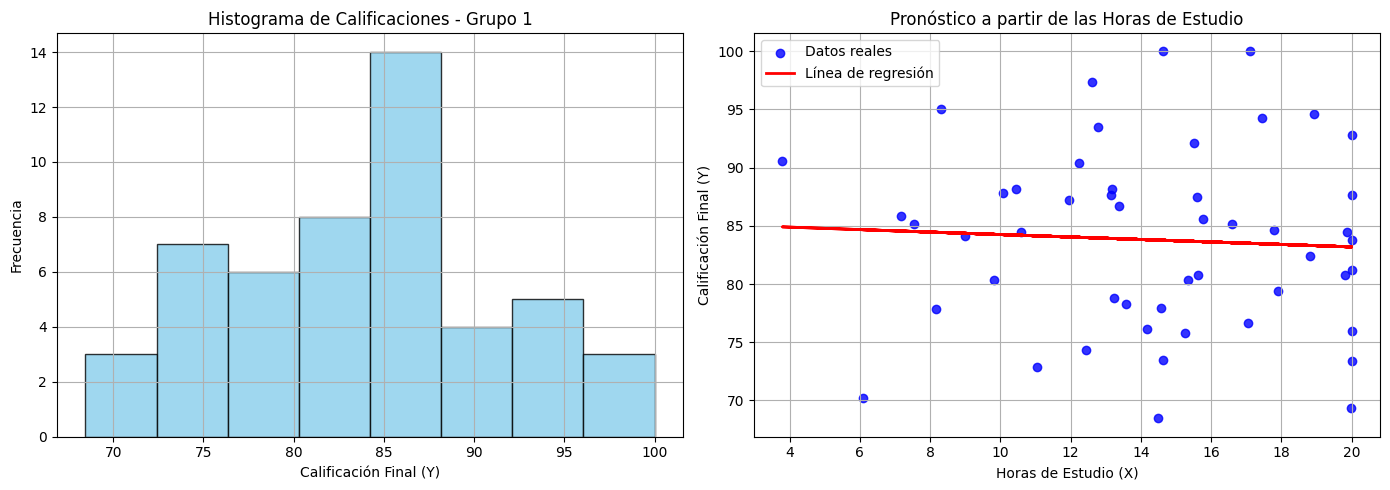

In [8]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from scipy.stats import pearsonr

df = pd.read_csv('grupo1.csv')

print("="*60)
print("DATOS INICIALES - GRUPO 1")
print("="*60)
print(df.head())
print("Descripción estadística")
print(df.describe())

X = df[['HorasEstudio']].values.reshape(-1, 1)
y = df['Calificacion'].values

modelo = LinearRegression()
modelo.fit(X, y)

intercepcion_a = modelo.intercept_
pendiente_b = modelo.coef_[0]
print("\n" + "="*60)
print("RESULTADOS DEL MODELO DE REGRESIÓN LINEAL")
print("="*60)
print(f"Intercepción (a): {intercepcion_a:.4f}")
print(f"Pendiente (b): {pendiente_b:.4f}")
print(f"Ecuación de regresión estimada: Y = {intercepcion_a:.4f} + {pendiente_b:.4f}X")

coef_corr, p_valor = pearsonr(df['HorasEstudio'], df['Calificacion'])
r_cuadrada = coef_corr ** 2
print("\n" + "="*60)

print("ANÁLISIS DE CORRELACIÓN Y DETERMINACIÓN")
print("="*60)
print(f"Coeficiente de Correlación de Pearson (r): {coef_corr:.4f}")
print(f"Coeficiente de Determinación (r^2): {r_cuadrada:.4f} ({r_cuadrada*100:.2f}%)")
print(f"Valor p (Significancia estadística): {p_valor:.4e}")

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.hist(y, bins=8, color='skyblue', edgecolor='black', alpha=0.8)
plt.title('Histograma de Calificaciones - Grupo 1')
plt.xlabel('Calificación Final (Y)')
plt.ylabel('Frecuencia')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.scatter(X, y, color='blue', label='Datos reales', alpha=0.8)
plt.plot(X, modelo.predict(X), color='red', linewidth=2, label='Línea de regresión')
plt.title('Pronóstico a partir de las Horas de Estudio')
plt.xlabel('Horas de Estudio (X)')
plt.ylabel('Calificación Final (Y)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()